In [1]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')

from utils.suite2p import split_suite2p_recordings

joint_plane0_dir = r'D:\data-distance-coding-project\raw-data\260326_SAM044_distance-normal-reverse\suite2p\plane0'
output_dirs = [r'D:\data-distance-coding-project\processed-data\260326_SAM044_distance-normal',
            r'D:\data-distance-coding-project\processed-data\260326_SAM044_distance-reverse']
frame_counts = [12058, 12058]

split_suite2p_recordings(joint_plane0_dir, output_dirs, frame_counts)

Recording 1: 12058 frames → D:\data-distance-coding-project\processed-data\260326_SAM044_distance-normal
Recording 2: 12058 frames → D:\data-distance-coding-project\processed-data\260326_SAM044_distance-reverse
Done. 4898 cells split into 2 recordings.


In [1]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.data.RadialDevice import RadialDevice
from src.analysis.CellAnalysis import CellAnalyzer, SessionAnalyzer
from src.viz.CellVisualizer import CellVisualizer
from src.viz.SessionVisualizer import SingleSessionVisualizer
from src.workflows import analyze_session
import numpy as np
import matplotlib.pyplot as plt
import pickle
from utils.suite2p import split_suite2p_recordings

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM044'
record_date = '260903'

df_temporal, device_temporal = analyze_session(mouse_name=mouse_name, record_date=record_date,
                                                experiment_name='distance-temporal', show_plots=False)
df_nasal, device_nasal = analyze_session(mouse_name=mouse_name, record_date=record_date,
                                                experiment_name='distance-nasal', show_plots=False)

Directory results already exists
[ok] Loading existing DataFrame from D:/data-distance-coding-project/processed-data\260903_SAM044_distance-temporal\260903_SAM044_distance-temporal_dataframe.pkl
Directory results already exists
[ok] Loading existing DataFrame from D:/data-distance-coding-project/processed-data\260903_SAM044_distance-nasal\260903_SAM044_distance-nasal_dataframe.pkl


In [2]:
session_temporal = SingleSessionVisualizer(df_temporal)
session_nasal = SingleSessionVisualizer(df_nasal)

C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\viz\SessionVisualizer.py:696: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


(<Figure size 800x500 with 1 Axes>,
 <PolarAxes: title={'center': 'Binocular'}, ylabel='Preferred Distance'>)

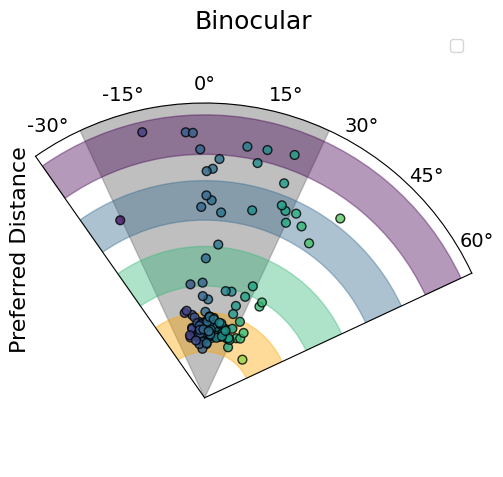

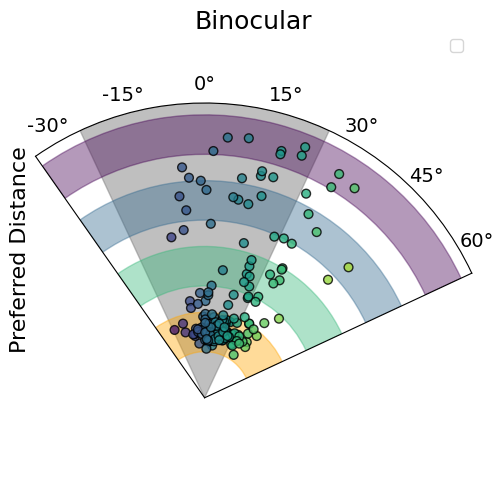

In [3]:
session_temporal.plot_preferred_distance_polar()
session_nasal.plot_preferred_distance_polar()

In [8]:
def plot_rf_histogram(self, condition='binocular', bins=20, ax=None, color='steelblue'):
    df = self.reliable_classes['reliable']
    rf_vals = self.extract_condition_feature(df, condition=condition, feature='RF')
    rf_vals = rf_vals[~np.isnan(rf_vals)]

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))
    else:
        fig = ax.get_figure()

    ax.hist(rf_vals, bins=bins, color=color, edgecolor='black', linewidth=0.5)
    ax.set_xlabel('RF Position (°)', fontsize=16)
    ax.set_ylabel('Number of Cells', fontsize=16)
    ax.tick_params(labelsize=12)
    ax.set_title(self._get_session_title(), fontsize=14, color='grey', pad=2)
    fig.suptitle(f'RF Distribution — {condition.capitalize()}', fontsize=18, fontweight='bold')
    plt.tight_layout()
    return fig

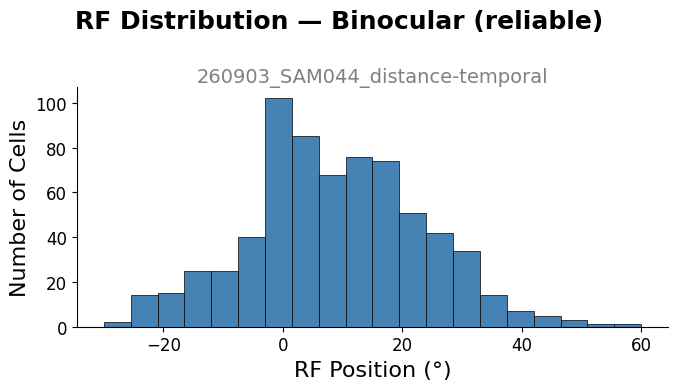

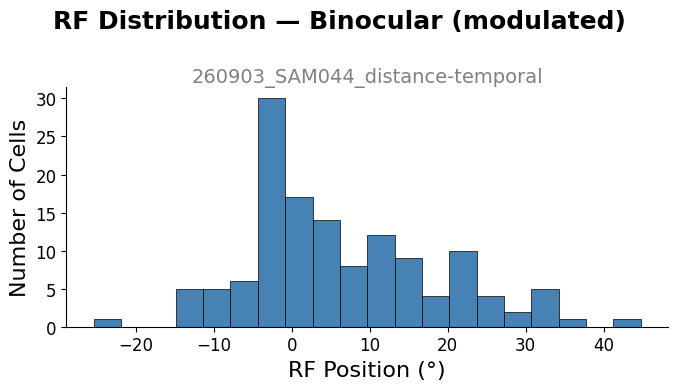

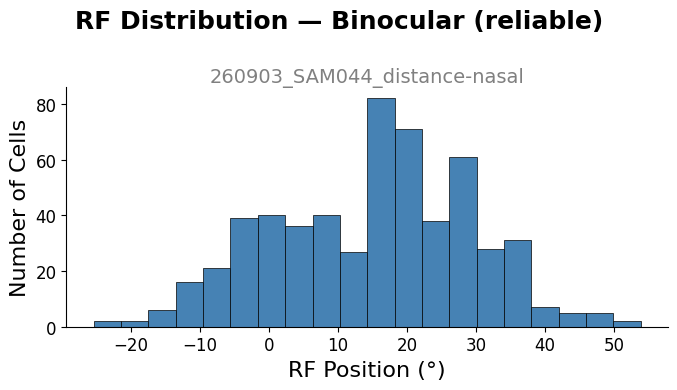

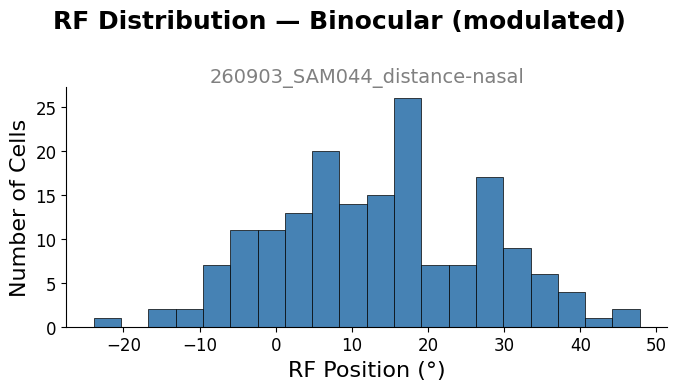

In [9]:
fig = session_temporal.plot_rf_histogram(subset='reliable')
fig = session_temporal.plot_rf_histogram(subset='modulated')
fig = session_nasal.plot_rf_histogram(subset='reliable')
fig = session_nasal.plot_rf_histogram(subset='modulated')

In [11]:
temporal_bino_ids = set(session_temporal.modulated_classes['binocular']['cell_id'].values)
nasal_bino_ids = set(session_nasal.modulated_classes['binocular']['cell_id'].values)

both_ids    = temporal_bino_ids & nasal_bino_ids
only_temporal = temporal_bino_ids - nasal_bino_ids
only_nasal = nasal_bino_ids - temporal_bino_ids

print(f"Binocular in both:         {len(both_ids)}")
print(f"Binocular only in normal:  {len(only_temporal)}")
print(f"Binocular only in reverse: {len(only_nasal)}")
print(f"Total cells: {len(both_ids) + len(only_temporal) + len(only_nasal)}")

Binocular in both:         30
Binocular only in normal:  104
Binocular only in reverse: 145
Total cells: 279


In [20]:
results_dir = r"D:\data-distance-coding-project\processed-data\260903_SAM044_distance-temporal\results"

from src.utils import create_new_result_dir

cell_viz_normal  = CellVisualizer(device_temporal)
cell_viz_reverse = CellVisualizer(device_nasal)

dirs = {
    'both':         create_new_result_dir(results_dir, 'both'),
    'only_temporal':  create_new_result_dir(results_dir, 'only_temporal'),
    'only_nasal': create_new_result_dir(results_dir, 'only_nasal'),
}
groups = {
    'both':         both_ids,
    'only_temporal':  only_temporal,
    'only_nasal': only_nasal,
}

from src.viz.CrossSessionVisualizer import CrossSessionVisualizer

cell_viz_temporal = CellVisualizer(device_temporal)  # RadialDevice for distance-temporal
cell_viz_nasal    = CellVisualizer(device_nasal)     # RadialDevice for distance-nasal

cross_viz = CrossSessionVisualizer([
    ('temporal', cell_viz_temporal),
    ('nasal',    cell_viz_nasal),
])

for group, cell_ids in groups.items():
    print(f'{group}: {len(cell_ids)} cells')
    for cell_id in cell_ids:
        for suffix, viz in [('temporal', cell_viz_normal), ('nasal', cell_viz_reverse)]:
            # fig = viz.plot_all_traces_colormap_distances(cell_id)
            # fig.savefig(os.path.join(dirs[group], f'cell_{cell_id}_{suffix}.png'), bbox_inches='tight', dpi=150)
            # plt.close(fig)
            fig = cross_viz.plot_cell(cell_id, conditions=['binocular'])
            fig.savefig(os.path.join(dirs[group], f'cell_{cell_id}_combined.png'), bbox_inches='tight', dpi=150)
            plt.close(fig)

        print(f'  cell {cell_id} done')

Creating directory: both
Creating directory: only_temporal
Creating directory: only_nasal
both: 30 cells
  cell 642 done
  cell 133 done
  cell 265 done
  cell 1289 done
  cell 270 done
  cell 399 done
  cell 656 done
  cell 1424 done
  cell 1046 done
  cell 156 done
  cell 34 done
  cell 802 done
  cell 933 done
  cell 561 done
  cell 1205 done
  cell 313 done
  cell 705 done
  cell 708 done
  cell 981 done
  cell 473 done
  cell 602 done
  cell 503 done
  cell 612 done
  cell 103 done
  cell 616 done
  cell 498 done
  cell 371 done
  cell 1013 done
  cell 375 done
  cell 255 done
only_temporal: 104 cells
  cell 512 done
  cell 513 done
  cell 519 done
  cell 9 done
  cell 1036 done
  cell 530 done
  cell 532 done
  cell 1048 done
  cell 1049 done
  cell 27 done
  cell 541 done
  cell 552 done
  cell 553 done
  cell 1074 done
  cell 564 done
  cell 1077 done
  cell 568 done
  cell 63 done
  cell 577 done
  cell 68 done
  cell 69 done
  cell 582 done
  cell 1102 done
  cell 82 done
  c

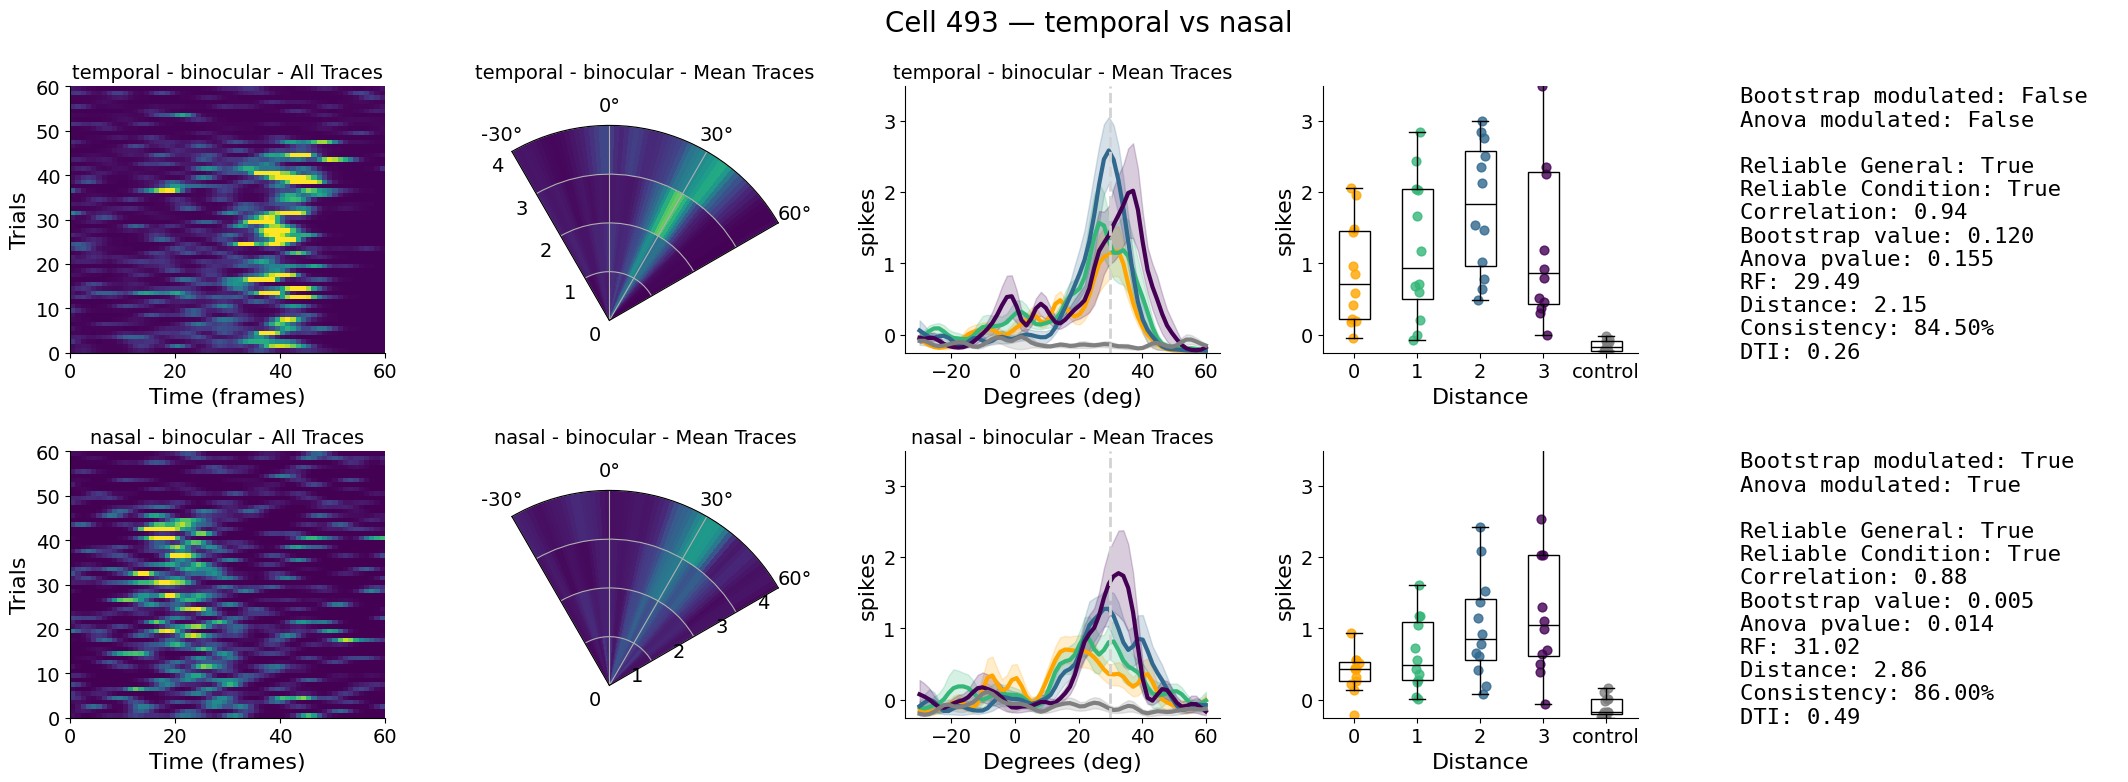

In [15]:
from src.viz.CrossSessionVisualizer import CrossSessionVisualizer

cell_viz_temporal = CellVisualizer(device_temporal)  # RadialDevice for distance-temporal
cell_viz_nasal    = CellVisualizer(device_nasal)     # RadialDevice for distance-nasal

cross_viz = CrossSessionVisualizer([
    ('temporal', cell_viz_temporal),
    ('nasal',    cell_viz_nasal),
])

fig = cross_viz.plot_cell(cell_id, conditions=['binocular'])

## Decoding using All Cells

In [23]:
import numpy as np
from src.decoding.Decoders import TrialDecoder, FactoredMLE, AveragedDecoder

# ── helper: build decoder data from a RadialDevice + stats dataframe ─────────
def build_decoder_data(device, session_df):
    """Returns X (n_neurons, n_positions, n_trials), y_dist (n_trials,),
    distances (n_distances,), angle_axis (n_positions,)."""
    # Reliable binocular cells
    def _reliable(row):
        v = row['binocular']
        return isinstance(v, dict) and v.get('reliable', False)
    cell_ids = session_df[session_df.apply(_reliable, axis=1)]['cell_id'].values

    # Binocular trial indices (monocular == 0), exclude control (distance == 4)
    mono_seq = np.array(device.monocular_sequence)
    dist_seq  = np.array(device.distance_sequence)
    trial_mask = (mono_seq == 0) & (dist_seq != 4)
    trial_idx  = np.where(trial_mask)[0]
    y_distance = dist_seq[trial_mask]

    # Build X
    traces = []
    for cell_id in cell_ids:
        cell_idx = np.where(device.suite2p_id == cell_id)[0][0]
        cell_traces = np.stack(
            [device.get_on_trace(cell_idx, int(r)) for r in trial_idx], axis=0
        )  # (n_trials, n_positions)
        traces.append(cell_traces)

    X = np.stack(traces, axis=0)          # (n_neurons, n_trials, n_positions)
    X = X.transpose(0, 2, 1)             # (n_neurons, n_positions, n_trials)

    n_positions = X.shape[1]
    angle_axis = np.linspace(float(device.start_angle), float(device.end_angle), n_positions)
    distances  = np.unique(y_distance)

    return X, y_distance, distances, angle_axis

class _SingleSessionAgg:
    def __init__(self, X, y_distance, distances, angle_axis, df):
        self._X         = X
        self._y         = y_distance
        self._df        = df
        self.distances  = distances
        self.angle_axis = angle_axis
        self.trial_info = {}

    @property
    def n_positions(self):
        return len(self.angle_axis)

    def _get_cell_indices(self, area=None, session=None):
        return list(range(self._X.shape[0]))

    def get_decoder_data(self, monocular=None, area=None, session=None, **kwargs):
        return self._X, self._y

    def get_split_decoder_data(self, monocular=None, area=None, session=None,
                               distances=None, test_fraction=0.5, random_state=None, **kwargs):
        rng   = np.random.RandomState(random_state)
        X, y  = self._X, self._y
        dists = self.distances if distances is None else np.array(distances)

        train_avgs, test_avgs = [], []
        for d in dists:
            idx = np.where(y == d)[0]
            rng.shuffle(idx)
            split = max(1, int(len(idx) * (1 - test_fraction)))
            train_avgs.append(X[:, :, idx[:split]].mean(axis=2))
            test_avgs.append( X[:, :, idx[split:]].mean(axis=2))

        return np.stack(train_avgs, axis=2), np.stack(test_avgs, axis=2), dists



# ── run ──────────────────────────────────────────────────────────────────────
X_n, y_n, dist_n, ang_n = build_decoder_data(device_temporal,  df_temporal)
X_r, y_r, dist_r, ang_r = build_decoder_data(device_nasal, df_nasal)

agg_temporal  = _SingleSessionAgg(X_n, y_n, dist_n, ang_n, df_temporal)
agg_nasal = _SingleSessionAgg(X_r, y_r, dist_r, ang_r, df_nasal)

print(f"Temporal:  {X_n.shape[0]} cells, {X_n.shape[2]} trials")
print(f"Nasal: {X_r.shape[0]} cells, {X_r.shape[2]} trials")

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_33132\1129401530.py:34: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  angle_axis = np.linspace(float(device.start_angle), float(device.end_angle), n_positions)


Temporal:  868 cells, 48 trials
Nasal: 847 cells, 48 trials


In [22]:
def align_results(*results):
    n_pos = min(res['angle_axis'].shape[0] for res in results)
    aligned = []
    for res in results:
        a = {**res, 'angle_axis': res['angle_axis'][:n_pos]}
        for key in ('pred_dist', 'pred_angle'):
            if key in res:
                a[key] = res[key][..., :n_pos]
        for key in ('true_dist', 'true_angle'):
            if key in res and res[key].ndim > 1:  # only truncate if has positions axis (AveragedDecoder)
                a[key] = res[key][..., :n_pos]
        for key in ('angle_mae_by_pos', 'dist_acc_by_pos'):
            if key in res:
                a[key] = res[key][:n_pos]
        aligned.append(a)
    return aligned

In [24]:
TrialDec = TrialDecoder()

trial_temporal = TrialDec.cross_validate(agg_temporal, monocular=0, loo=True)
trial_nasal = TrialDec.cross_validate(agg_nasal, monocular=0, loo=True)

trial_temporal, trial_nasal = align_results(trial_temporal, trial_nasal)

Trial 48/48
  Angle MAE:    5.01°
  Dist Acc:     30.3%
Trial 48/48
  Angle MAE:    3.63°
  Dist Acc:     42.8%


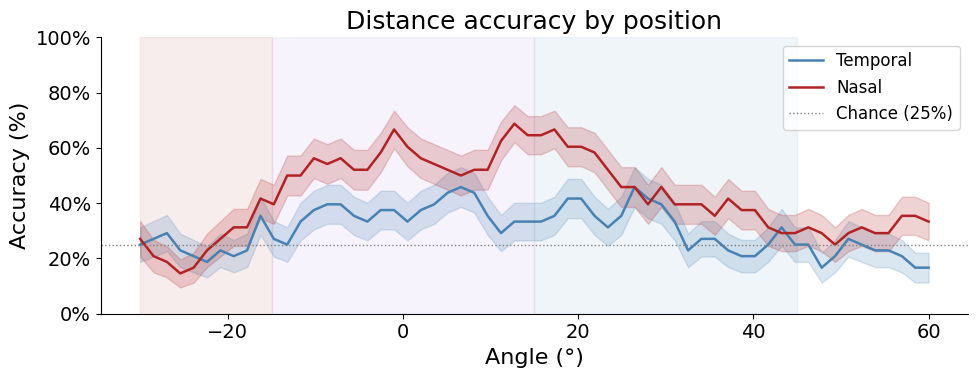

In [25]:
fig = TrialDec.plot_distance_results(trial_temporal, trial_nasal, labels=['Temporal', 'Nasal'])

In [28]:
AvgDec = AveragedDecoder()

averaged_temporal = AvgDec.cross_validate(agg_temporal, monocular=0, n_repeats = 20)
averaged_nasal = AvgDec.cross_validate(agg_nasal, monocular=0, n_repeats = 20)

Repeat 20/20
  Angle MAE:    3.77°
  Dist Acc:     30.0%
Repeat 20/20
  Angle MAE:    1.29°
  Dist Acc:     51.3%


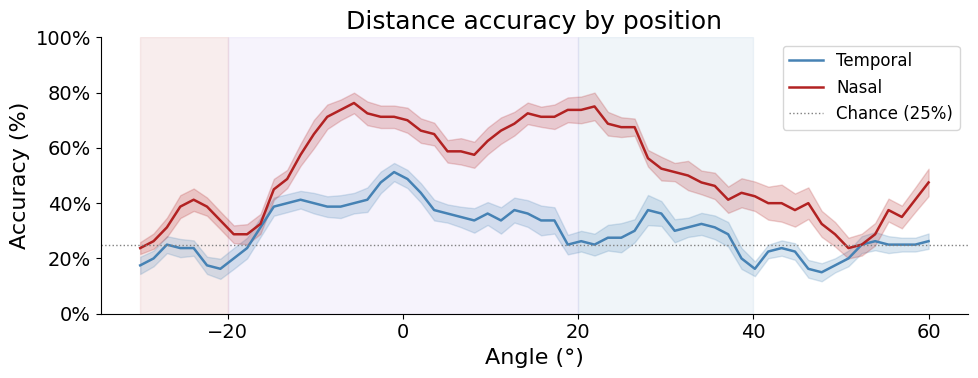

In [30]:
trial_temporal, trial_nasal = align_results(trial_temporal, trial_nasal)
averaged_temporal, averaged_reverse = align_results(averaged_temporal, averaged_nasal)

fig = AvgDec.plot_distance_results(averaged_temporal, averaged_reverse, labels=['Temporal', 'Nasal'])

In [ ]:
# Decoding using top cells

In [58]:
# --- cell indices shared by decoder ---

def get_top_dti_cells(agg, k_cells):
    _cell_idx_list = agg._get_cell_indices(area=None)

    # DTI ranking
    bino_dti      = agg._df.loc[_cell_idx_list, 'binocular'].apply(lambda d: d['DTI']).values
    rank_dti_desc = np.argsort(bino_dti)[::-1]

    cell_idx = rank_dti_desc[:k_cells]

    return cell_idx

def get_top_corr_cells(agg, k_cells):

    _cell_idx_list = agg._get_cell_indices(area=None)

    # DTI ranking
    bino_dti      = agg._df.loc[_cell_idx_list, 'binocular'].apply(lambda d: d['reliable_corr']).values
    rank_corr_desc = np.argsort(bino_dti)[::-1]

    cell_idx = rank_corr_desc[:k_cells]

    return cell_idx

top_normal_cells = get_top_corr_cells(agg_normal, 100)
top_reverse_cells = get_top_corr_cells(agg_reverse, 100)

In [57]:
print(df_normal['binocular'][0].keys())

dict_keys(['RF', 'reliable', 'reliable_corr', 'bootstrap_pvalue', 'anova_pvalue', 'consistency', 'DTI', 'distance'])


Repeat 10/10
  Angle MAE:    2.03°
  Dist Acc:     36.9%
Repeat 10/10
  Angle MAE:    1.93°
  Dist Acc:     42.5%


C:\Users\acostamendoza\projects\distance-project\radial-analysis\src\decoding\Decoders.py:1299: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  


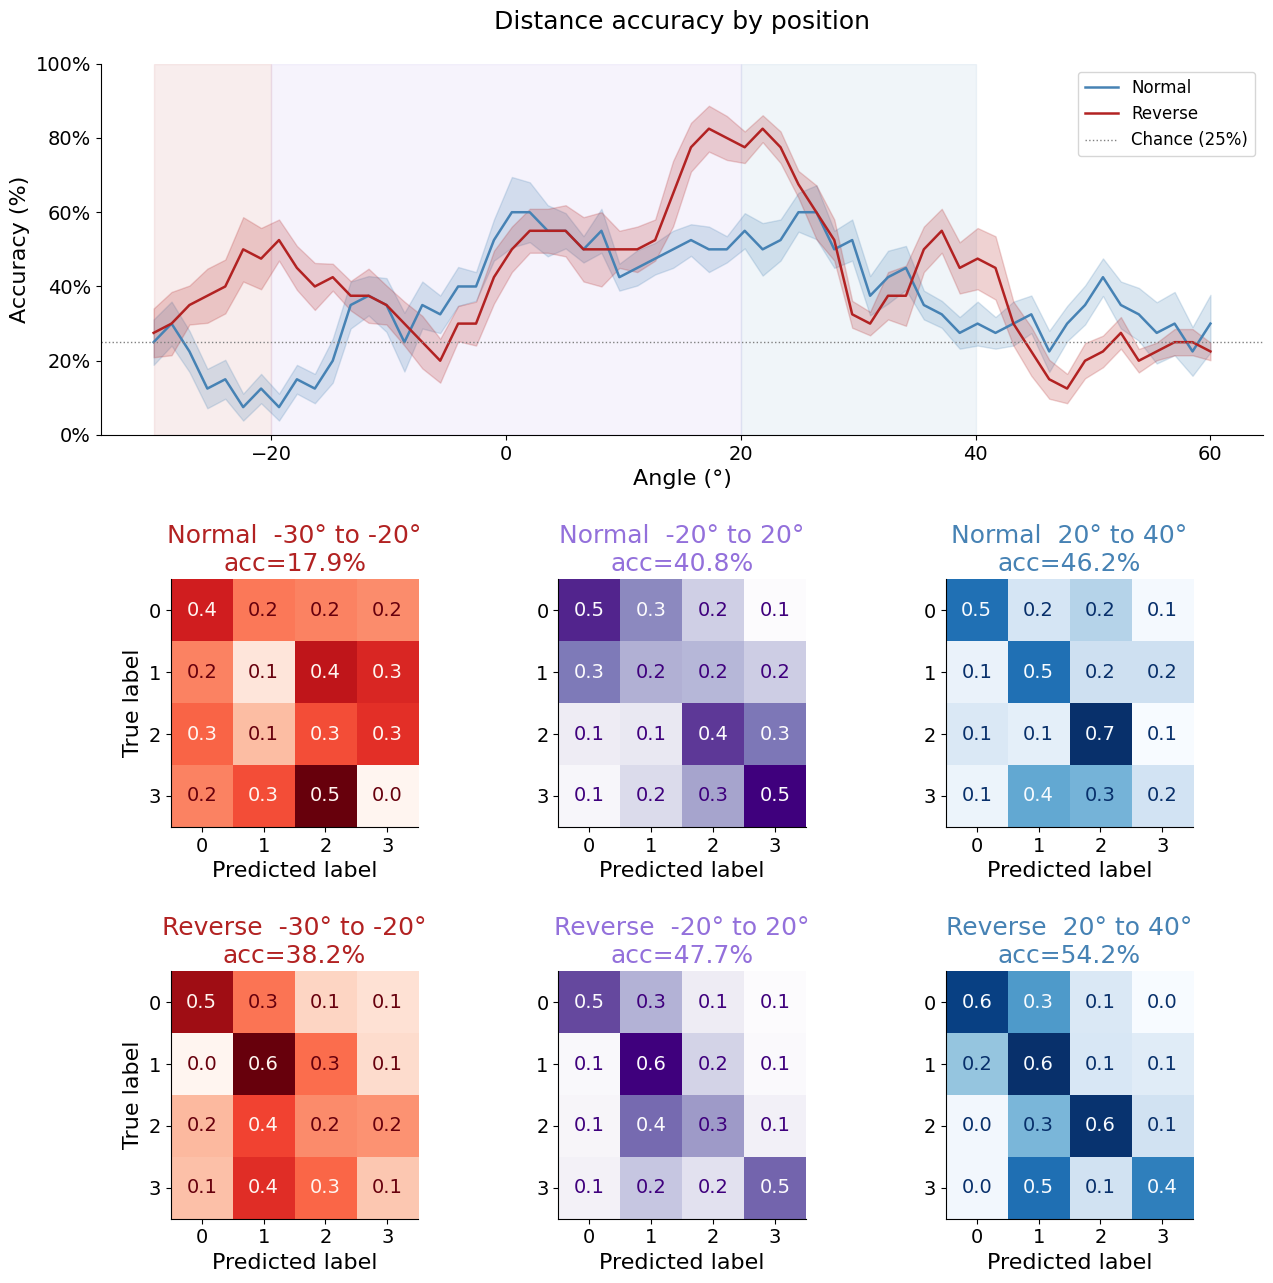

In [60]:
top_normal_cells = get_top_corr_cells(agg_normal, 100)
top_reverse_cells = get_top_corr_cells(agg_reverse, 100)

averaged_normal = AvgDec.cross_validate(agg_normal, monocular=0, cell_idx = top_normal_cells)
averaged_reverse = AvgDec.cross_validate(agg_reverse, monocular=0, cell_idx = top_reverse_cells)

averaged_normal, averaged_reverse = align_results(averaged_normal, averaged_reverse)
fig = AvgDec.plot_distance_results(averaged_normal, averaged_reverse, labels=['Normal', 'Reverse'])

ValueError: x and y must have same first dimension, but have shapes (4,) and (60,)

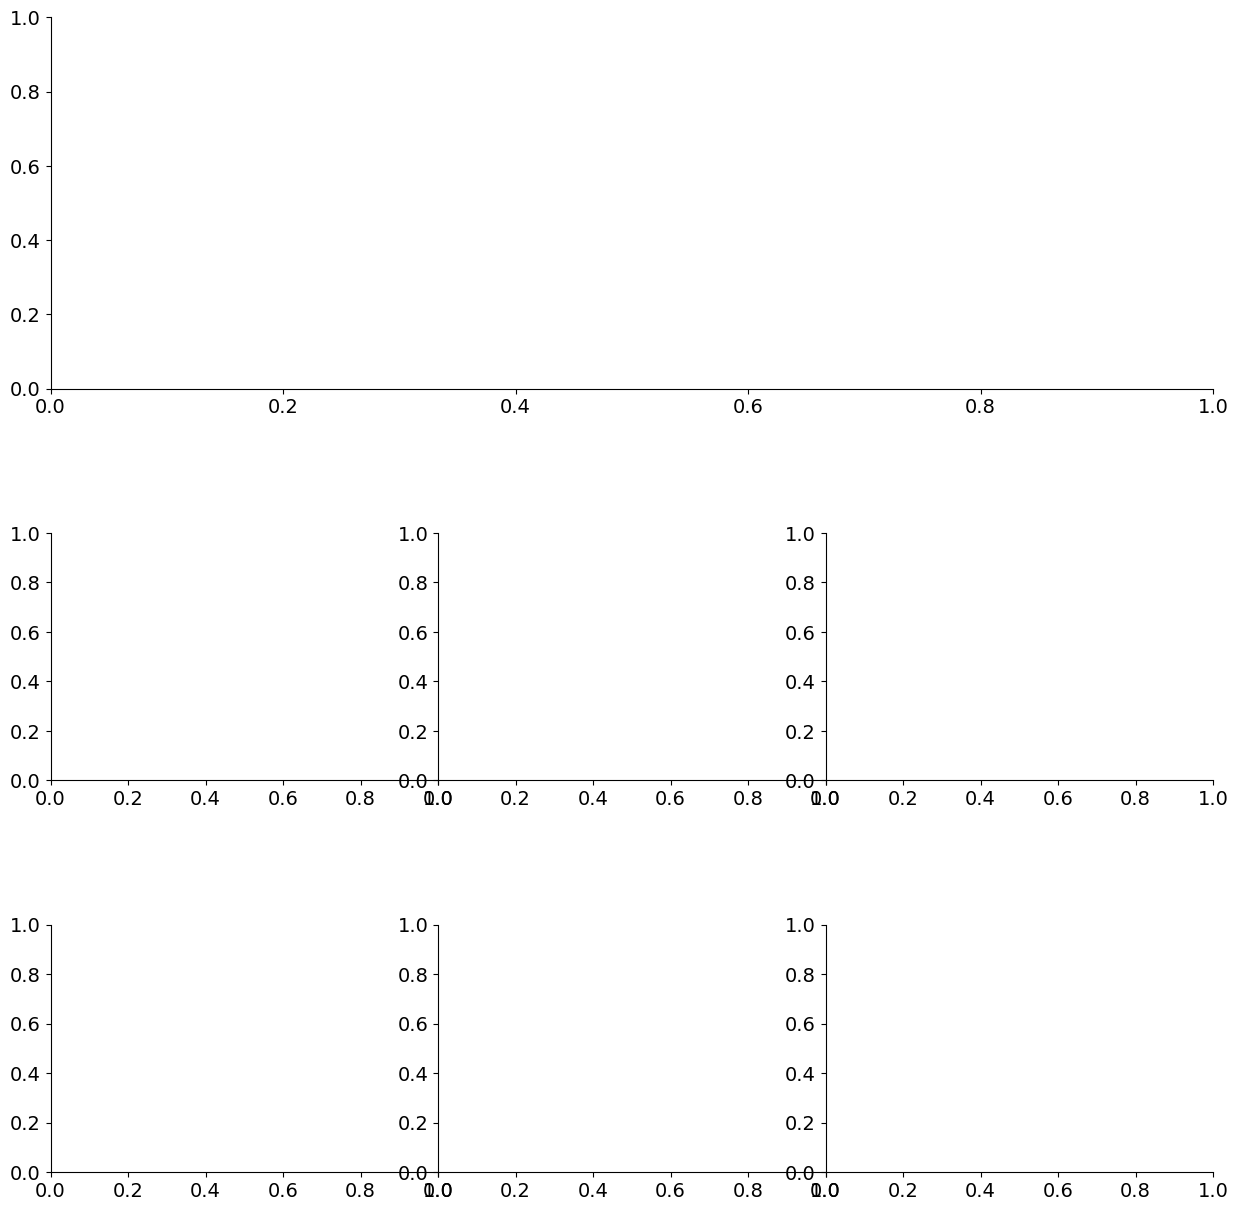

In [96]:
def align_results(*results):
    """Truncate all results to the minimum number of angle positions."""
    n_pos = min(res['pred_dist'].shape[1] for res in results)
    aligned = []
    for res in results:
        aligned.append({**res,
            'pred_dist':  res['pred_dist'][:, :n_pos],
            'pred_angle': res['pred_angle'][:, :n_pos],
            'true_angle': res['true_angle'][:, :n_pos],
            'angle_axis': res['angle_axis'][:n_pos],
            'angle_mae_by_pos': res['angle_mae_by_pos'][:n_pos],
            'dist_acc_by_pos':  res['dist_acc_by_pos'][:n_pos],
        })
    return aligned

normal_a, reverse_a = align_results(results_normal, results_reverse)
AvgDecoder.plot_distance_results(normal_a, reverse_a)

ValueError: x and y must have same first dimension, but have shapes (60,) and (61,)

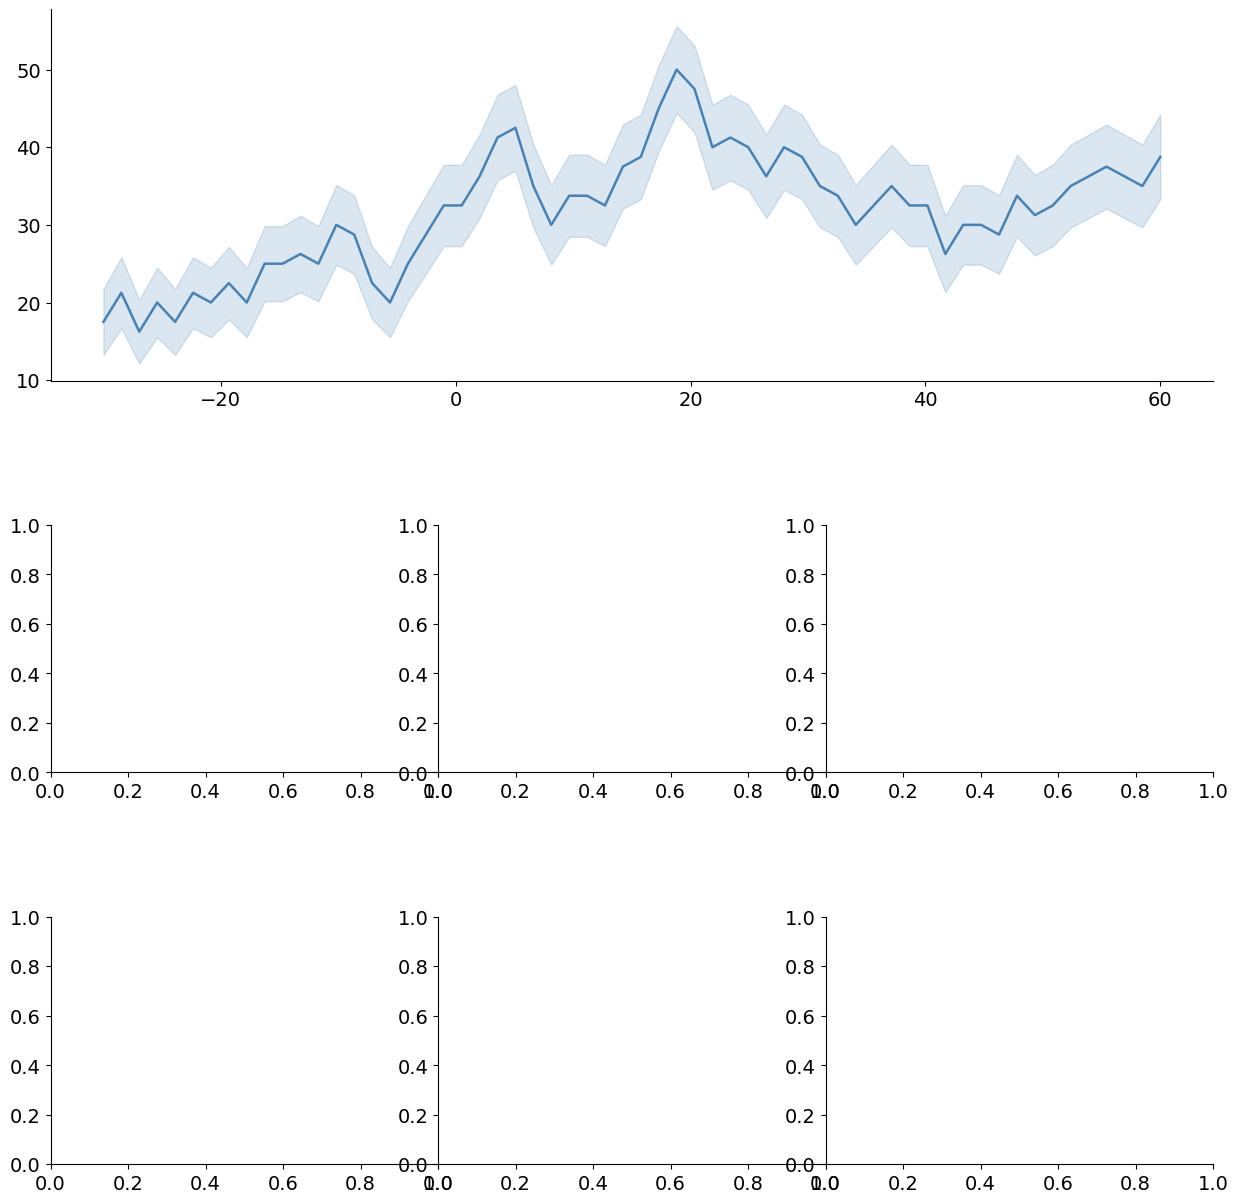

In [79]:
Decoder.plot_distance_results(normal, reverse)

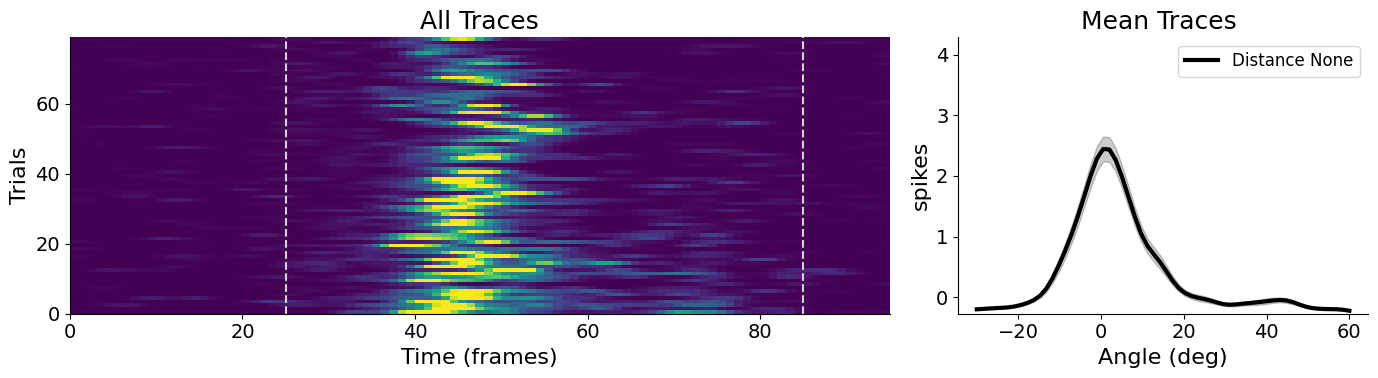

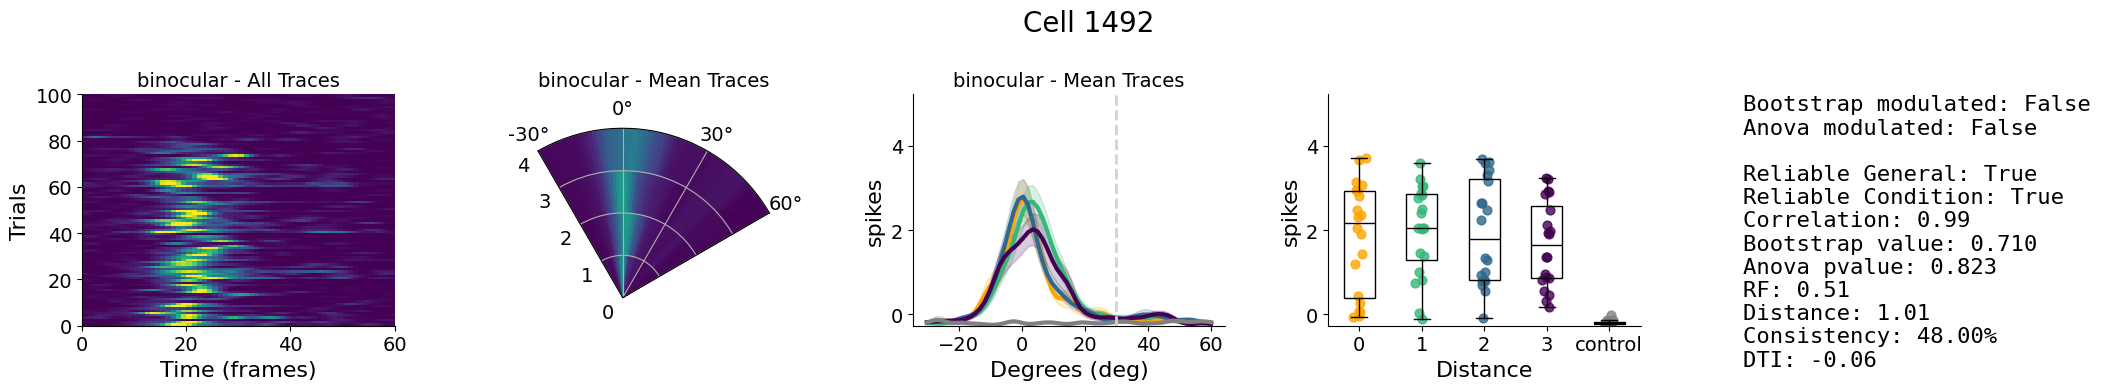

In [18]:
cell = 1492
fig = visualizer.plot_all_traces_colormap(cell=cell)
fig = visualizer.plot_all_traces_colormap_distances(cell = cell)

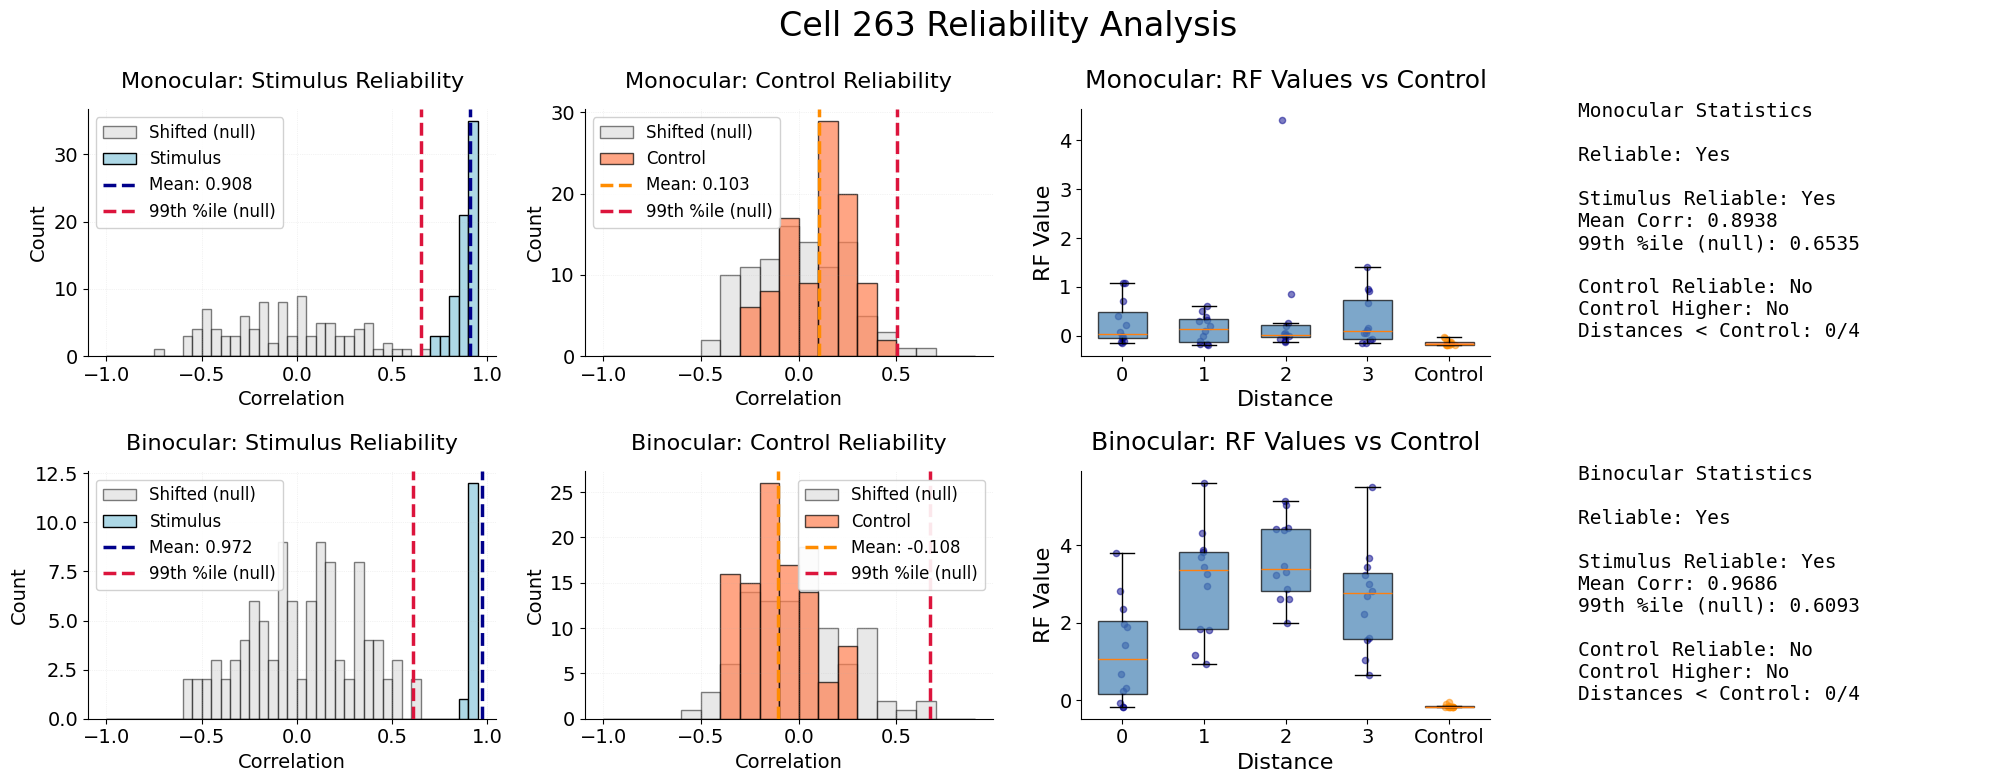

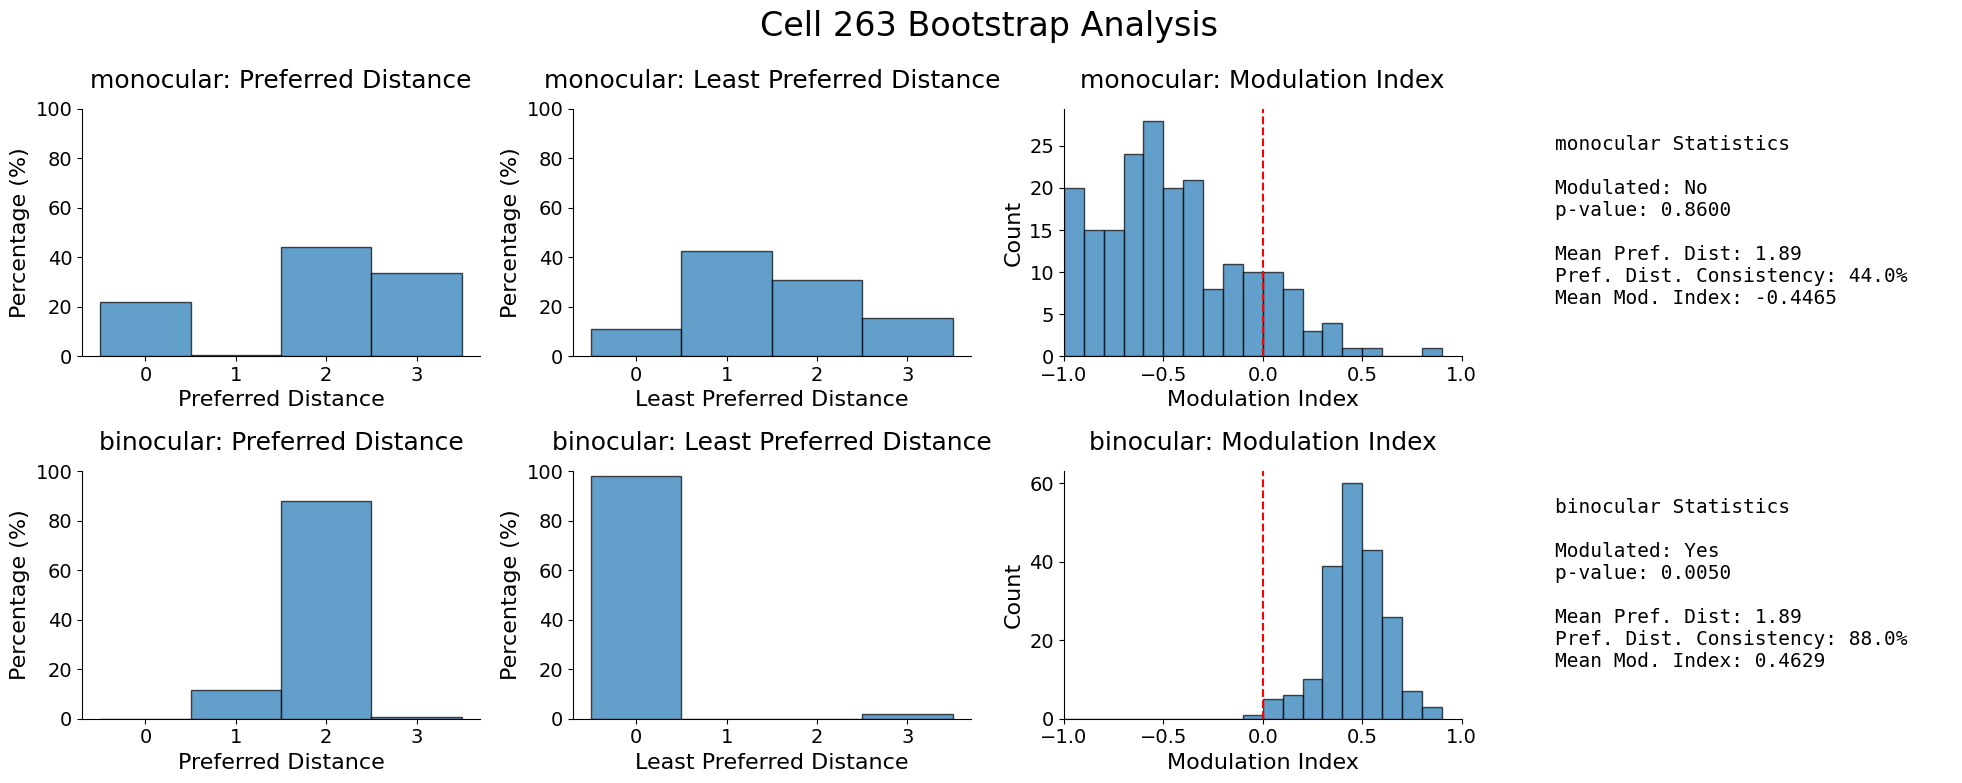

In [4]:
cell = 263
fig = visualizer.plot_reliability_analysis(cell = cell)
fig = visualizer.plot_bootstrap_modulation(cell = cell)